Imports

In [2]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

import matplotlib.pyplot as plt

Load dataset

In [4]:
df = pd.read_csv("bihar_flood_data.csv")  # change path
df.head()

,Date,District,Rainfall_mm,River_Level_m,Danger_Level_m,Flood,Population,Crop_Area_ha
0,2023-11-27,Araria,101.86,5.45,12.0,0,2794130,45827
1,2016-05-25,Purnia,67.95,5.67,12.0,0,1522966,57670
2,2016-01-05,Supaul,62.59,4.82,12.0,0,2428881,90847
3,2017-04-27,Begusarai,46.94,4.81,12.0,0,1743325,88113
4,2022-12-18,Jamui,48.06,4.69,12.0,0,2017991,52990


Handle Date

In [5]:
df['Date'] = pd.to_datetime(df['Date'])

df['year'] = df['Date'].dt.year
df['month'] = df['Date'].dt.month
df['day'] = df['Date'].dt.day

df = df.drop(columns=['Date'])

Encode District

In [6]:
df = pd.get_dummies(df, columns=['District'], drop_first=True)

Define Features & Target

In [7]:
X = df.drop(columns=['Flood'])
y = df['Flood']

Train-Test Split

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Scaling

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Train ANN

In [11]:
from sklearn.neural_network import MLPClassifier

ann_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
)

ann_model.fit(X_train, y_train)

MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)

Predictions

In [13]:
y_pred_ann = ann_model.predict(X_test)

Evaluation

In [14]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred_ann))
print("F1 Score:", f1_score(y_test, y_pred_ann))

print(classification_report(y_test, y_pred_ann))

Accuracy: 0.91875
F1 Score: 0.7560321715817694
              precision    recall  f1-score   support

           0       0.94      0.96      0.95       921
           1       0.81      0.71      0.76       199

    accuracy                           0.92      1120
   macro avg       0.87      0.84      0.85      1120
weighted avg       0.92      0.92      0.92      1120



Confusion Matrix

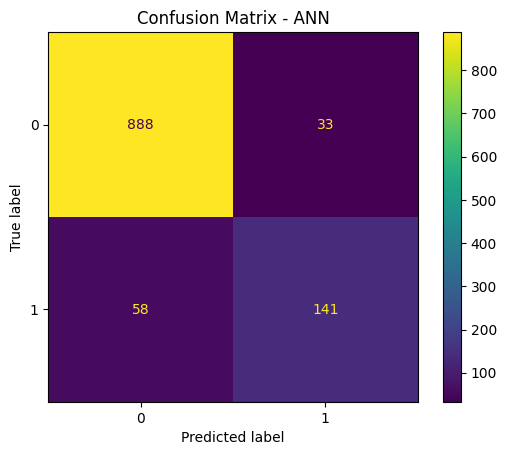

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_estimator(ann_model, X_test, y_test)
plt.title("Confusion Matrix - ANN")
plt.show()

ROC Curve

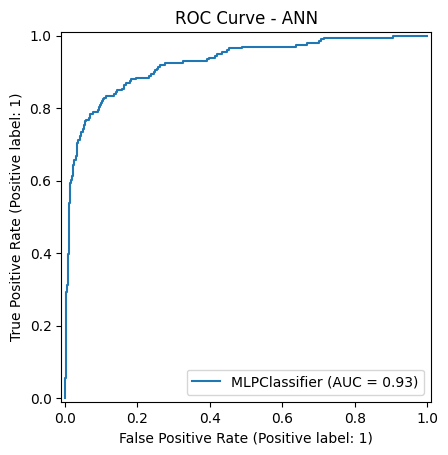

In [16]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(ann_model, X_test, y_test)
plt.title("ROC Curve - ANN")
plt.show()

Precision-Recall Curve

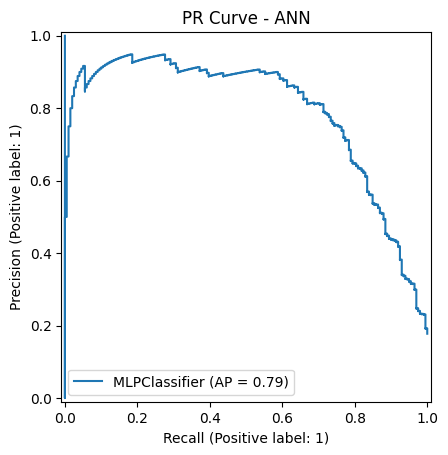

In [18]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_estimator(ann_model, X_test, y_test)
plt.title("PR Curve - ANN")
plt.show()